# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


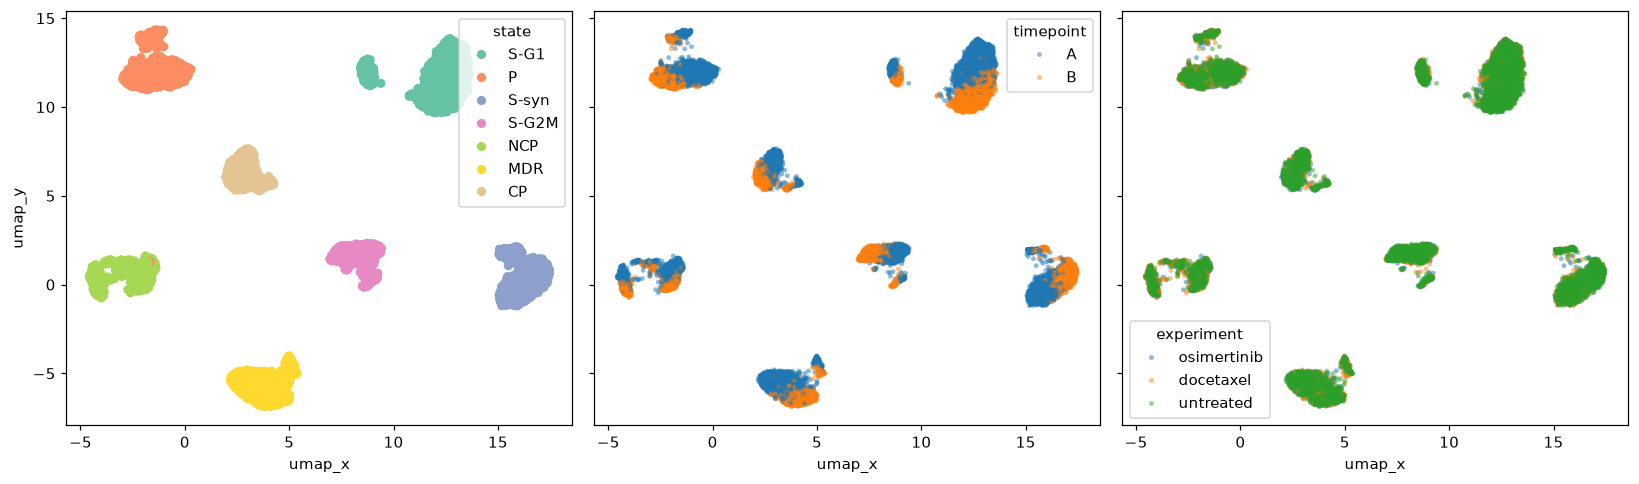

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

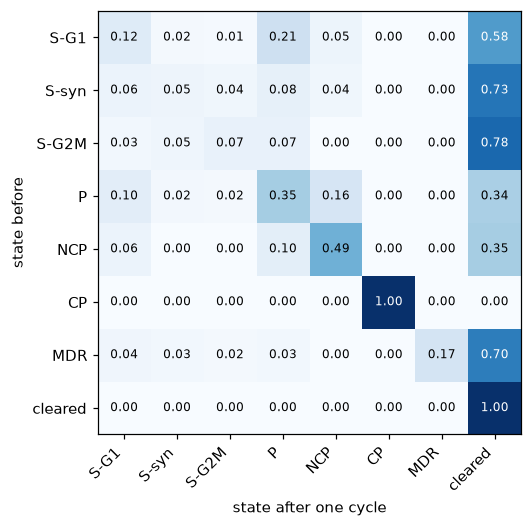

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Yes, we see that under CP, the osimertinib drug has no effect on the cells as we do not see it transition to another state. Once it started in CP, it does not transition to another state since we notice that the p hat in the matrix is 1. This means that the cell is resistant to the drug since it is not transitioning states after the drug has been given. The drug is not eliminating the cell since the cell did not enter the cleared state.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

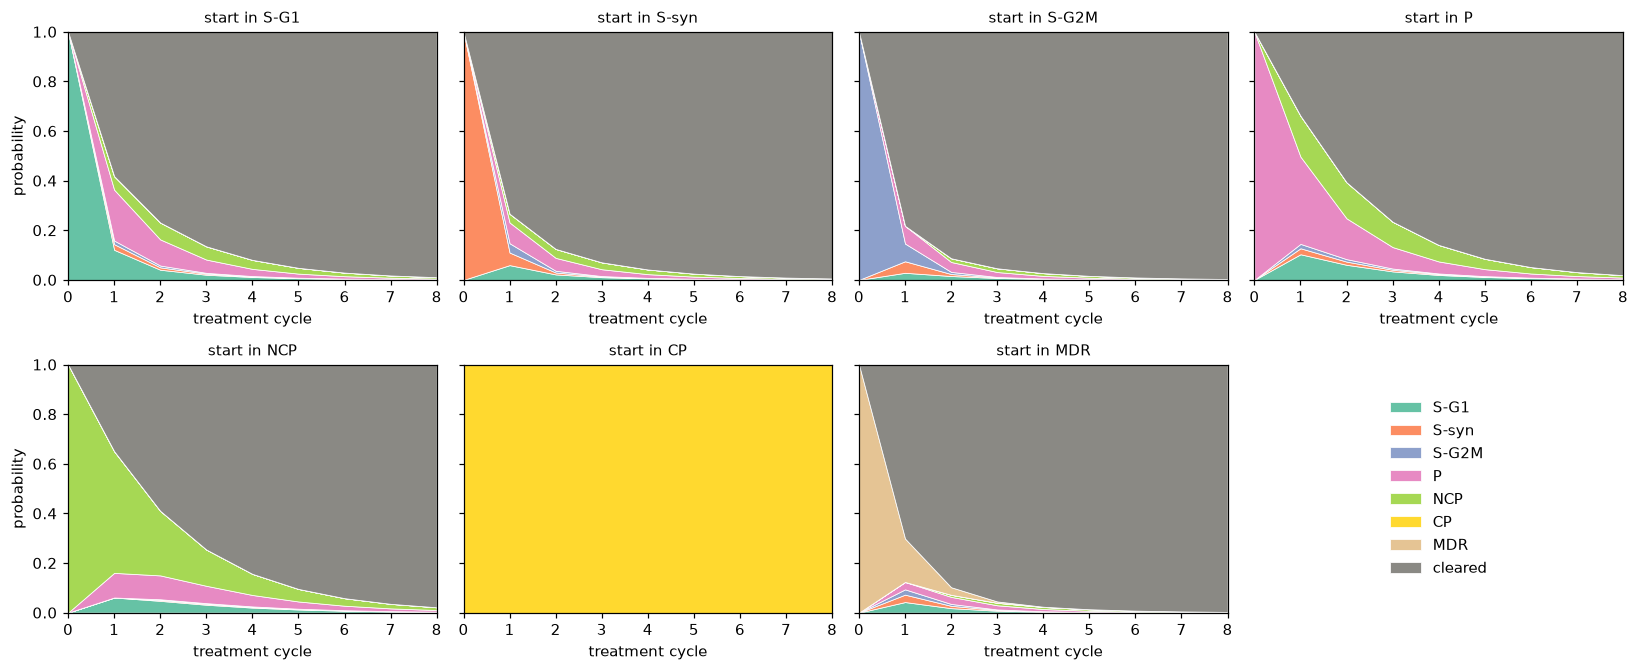

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

In [16]:

for state in STATES:
    result = evolve(basis(state, P_hat), P_hat, 8)
    cleared = result[-1, -1]

    print(state, round(cleared * 100, 2), "% cleared")


S-G1 98.92 % cleared
S-syn 99.44 % cleared
S-G2M 99.64 % cleared
P 98.1 % cleared
NCP 97.84 % cleared
CP 0.0 % cleared
MDR 99.71 % cleared


<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

Every state becomes mostly cleared except for the CP state. The CP state cells seem to survive despite the 8 treatment cycles given. 

I will say though that even with eight treatment cycles, we don't have all the cells completely cleared in each of the starting states. They are basically cleared, but not entirely. For instance, we know that S-G1 is 98.92% cleared, S-syn is 99.44% cleared, S-G2M is 99.64% cleared, NCP is 97.84% cleared, MDR is 99.71% cleared, and P is 98.1% cleared. However, this does not exactly mean that they have been completely cleared. 

- Of the states that can be cleared, which tumor lasts the longest?

It seems that the NCP state cells last the longest. We notice that it is only 97.84% cleared after the 8 treatment cycles while the rest of the cell states were more cleared than this after the eight treatment cycles.

- Which starting state sticks around for the most cycles of drug?

The CP state sticks around the most because it is the most resistant to the drug ana dwe don't see it become clear after the eight treatment cycles.

- Which starting state results in the highest proportion of alive cells after three cycles?

The CP state results in the highest proportion of alive cells after three cycles because none of the cells were cleared after the drug was applied. This mean the alive proportion should be 100% because there are 0 cells that were considered as cleared.

</div>



### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

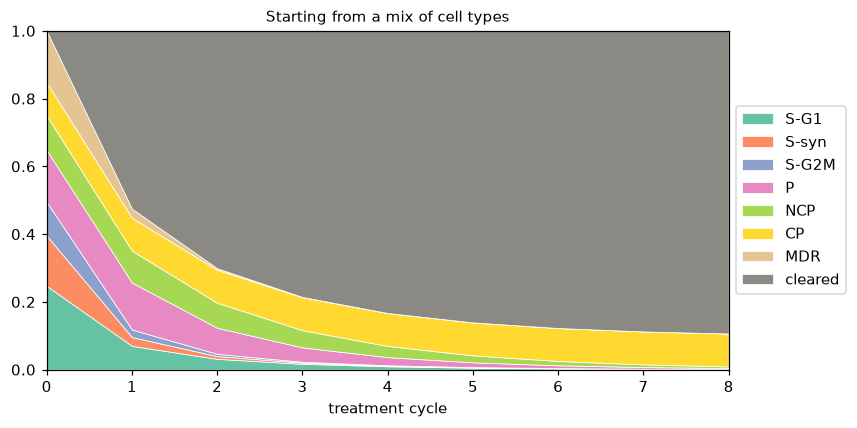

In [17]:
# Your code here

pi_mix = cells[cells["timepoint"] == "A"]["state"].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0).to_numpy()

# evolve pi_mix and plot the results
traj_mix = evolve(pi_mix, P_hat, 8)

fig, ax = plt.subplots(figsize=(8, 4))
plot_trajectory(traj_mix, ax, "Starting from a mix of cell types")

ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()

# TODO: set this equal to the starting vector from timepoint A


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

The CP ends up dominating the remaining cluster. We notice that it takes up the largest proportion of the living cells in the plot even towards the end of the eight treatments. I don't believe these will be cleared with the current treatment plan. We noticed before that it was resistant to the drug and none of the CP cells became cleared after the treatment was applied. As it hasn't changed across eight treatment cycles, I don't believe the CP cells will become cleared under this treatment plan. 

The long run endpoint can be shown through the transition matrix if we transition enough times to get to our endpoint. The long run endpoint represents the distribution of the cells after several transitions happened and once the probabilities have become stable. So, as the transition matrix represents the possibilities of changes, if we do enough transitions with the transition matrix, we will go from the starting state to an end state. The transition will be our way of getting to the end and so that's why we need the transition matrix to reach to the longrun end point. Our transition matrix represents the probabilities of the cells moving from one state to the next when one treatment cycle has occurred. So the application of this matrix will allow us understand the possibilities of distributions once we apply the probabilities in sequence to get to the endpoint. 

To drive the point even further, we know that once the cell enters the CP or the cleared state, it does not transition. So, once we notice that the cell distrbutions are basically within the cleared and CP state after using the transition matrix, then we know that we are currently approaching our long-run endpoint. The cells in CP or cleared won't transition further and they have mostly reached a state where we know that it will no longer change. However, it is important to note that the cells that are in other states can still transition, but there are very few of them towards the end of the eight treatments. So, this means that we are approaching the long-run endpoint because the distribution of cells is changing slightly with most cells being in either the CP or cleared state.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [18]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

def build_matrix(experiment):
    data = cells[cells["experiment"] == experiment]

    at_A = data[data["timepoint"] == "A"][["lineage_tag", "state"]]
    at_B = data[data["timepoint"] == "B"][["lineage_tag", "state"]]

    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left",
                     suffixes=("_A", "_B"))

    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = pd.crosstab(pairs["state_A"], pairs["state_B"])
    counts = counts.reindex(index=STATES, columns=OUTCOMES, fill_value=0)

    matrix = counts.div(counts.sum(axis=1), axis=0)
    matrix.loc["cleared"] = [0, 0, 0, 0, 0, 0, 0, 1]

    return matrix.to_numpy()

P_doc = build_matrix("docetaxel")      # TODO

P_holiday = build_matrix("untreated")  # TODO

# Add code here
# Keep these as 8x8 numpy arrays (with the cleared row)

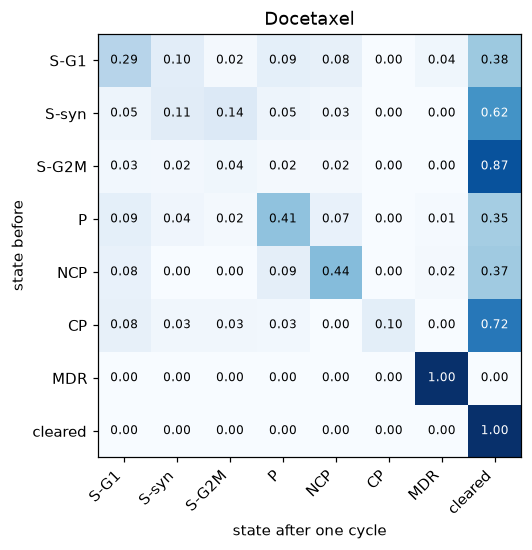

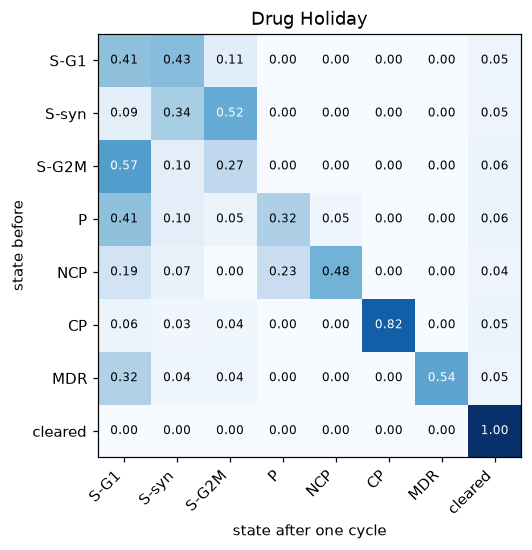

In [19]:
#Plot the transition matrices for docetaxel and the drug holiday.

doc_table = pd.DataFrame(P_doc, index=OUTCOMES, columns=OUTCOMES)
holiday_table = pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES)

show_matrix(doc_table, "Docetaxel")
plt.show()

show_matrix(holiday_table, "Drug Holiday")
plt.show()


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


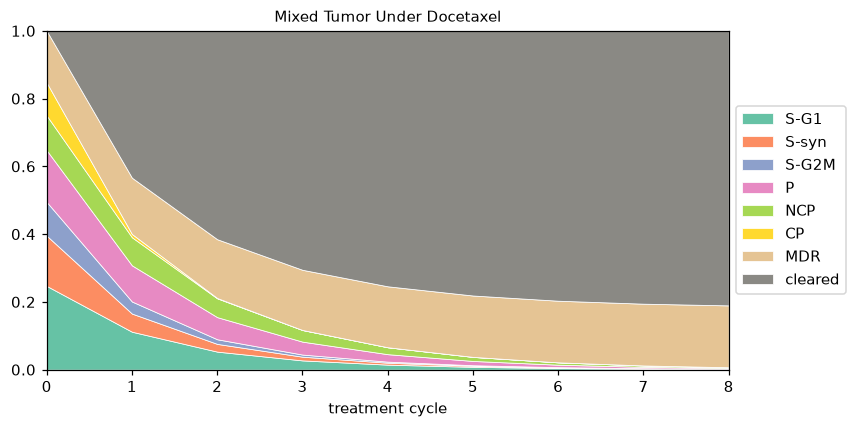

In [20]:
# Simulate the evolution of pi_mix under docetaxel 

traj_doc = evolve(pi_mix, P_doc, 8)

display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(8, 4))

plot_trajectory(traj_doc, ax, "Mixed Tumor Under Docetaxel")

ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()


1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

It seems like the docetaxel transition matrix looks similar to the osimertinib transition matrix with some differences. The docetaxel transition matrix does move the CP cell states to cleared more than the osimertinib did. However, I also noticed that most starting cells have higher transition probabilities to cleared under osimiertinib or docetaxel as we see a stronger blue and higher values in the cleared column with both transition matrixes. However, the one difference between these two that is extremely evident is that docetaxel shows that it can transition cells from CP to cleared at a higher probability than osimertinib. Osmiertinib can transition cells from MDR to cleared at a higher probability than docetaxel.

I know that with the docetaxel, the MDR and cleared are the absorbing states while with the osmiertinib, the CP and cleared are the absorbing states. 

Drug holiday and osmiertinib show a lot of difference. Under drug holiday, we can notice that a lot of the S-G1, MDR, P, and S-G2M transition to the S-G1. We do not notice that many cell states transitioning to the cleared column. However, I did notice that the CP cell state has a high transition probability to CP in both the osmiertinib and a drug holiday.

In the drug holiday, the only absorbing state is the cleared state. 

2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

We notice that the MDR cell state takes up most of the proportion of cell states which are living. Further, as the number of treatment cycles increases, more cells enter the MDR state or the cleared state. There are far less of each of the other states as the treatment cycles increase to 8. The reason that the MDR becomes the largest proportion with the living cell states is because it is an absorbing state.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [21]:
## Add code here

def run_schedule(start, treatments):
    results = [start]

    for drug in treatments:
        results.append(results[-1] @ drug)

    return np.array(results)


# 8 cycles of the same drug
osi8 = evolve(pi_mix, P_osi, 8)
doc8 = evolve(pi_mix, P_doc, 8)

# 8 cycles alternating between the two drugs
od8 = run_schedule(pi_mix, [P_osi, P_doc] * 4)
do8 = run_schedule(pi_mix, [P_doc, P_osi] * 4)

# Compare how many cells are cleared
print("Osimertinib:", round(osi8[-1, -1] * 100, 2), "%")
print("Docetaxel:", round(doc8[-1, -1] * 100, 2), "%")
print("Alternating O-D:", round(od8[-1, -1] * 100, 2), "%")
print("Alternating D-O:", round(do8[-1, -1] * 100, 2), "%")


Osimertinib: 89.34 %
Docetaxel: 81.04 %
Alternating O-D: 99.06 %
Alternating D-O: 99.08 %


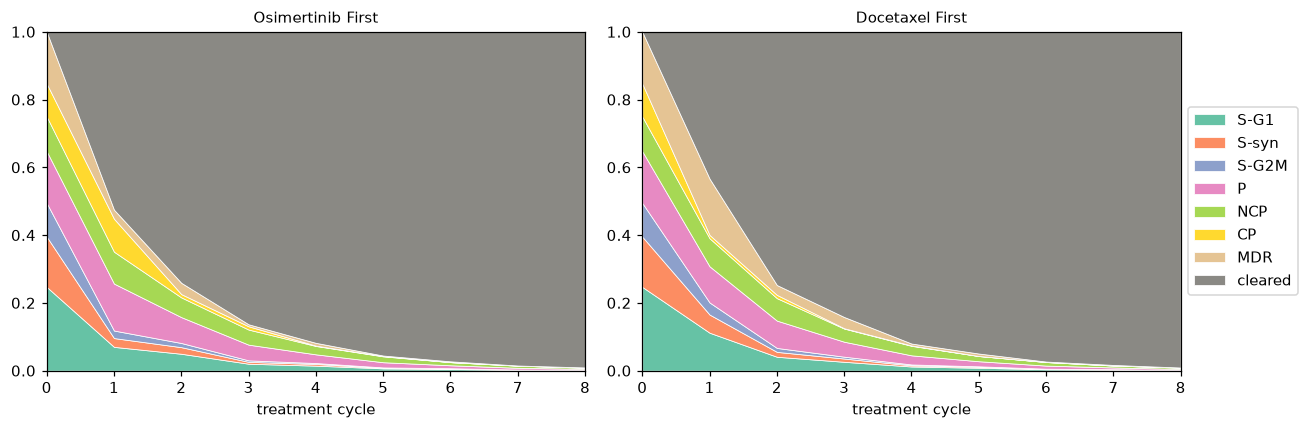

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_trajectory(od8, axes[0], "Osimertinib First")
plot_trajectory(do8, axes[1], "Docetaxel First")

axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()


In [23]:
# Start with 100% CP cells
cp_start = basis("CP", P_hat)

# Compare two schedules over 8 cycles
cp_osi = evolve(cp_start, P_osi, 8)

cp_holiday = run_schedule(cp_start, [P_osi, P_holiday] * 4)

print("Osimertinib only:",
      round(cp_osi[-1, -1] * 100, 2), "% cleared")

print("Osimertinib with holidays:",
      round(cp_holiday[-1, -1] * 100, 2), "% cleared")


Osimertinib only: 0.0 % cleared
Osimertinib with holidays: 43.18 % cleared


In [24]:

# Test different starting cell states
starting_states = ["S-G1", "CP", "MDR"]

# Test different treatment schedules
schedules = {
    "Osimertinib": [P_osi] * 8,
    "Docetaxel": [P_doc] * 8,
    "Alternating O-D": [P_osi, P_doc] * 4,
    "Alternating D-O": [P_doc, P_osi] * 4
}

for state in starting_states:
    print("\nStarting state:", state)

    start = basis(state, P_hat)

    for name, schedule in schedules.items():
        result = run_schedule(start, schedule)
        cleared = result[-1, -1] * 100

        print(name, round(cleared, 2), "% cleared")



Starting state: S-G1
Osimertinib 98.92 % cleared
Docetaxel 92.73 % cleared
Alternating O-D 99.01 % cleared
Alternating D-O 98.91 % cleared

Starting state: CP
Osimertinib 0.0 % cleared
Docetaxel 98.99 % cleared
Alternating O-D 99.36 % cleared
Alternating D-O 99.64 % cleared

Starting state: MDR
Osimertinib 99.71 % cleared
Docetaxel 0.0 % cleared
Alternating O-D 99.52 % cleared
Alternating D-O 99.27 % cleared


In [25]:

# Check clearance after each cycle for the mixed tumor
schedule = [P_osi, P_doc] * 4

for cycles in range(1, 9):
    result = run_schedule(pi_mix, schedule[:cycles])
    cleared = result[-1, -1] * 100

    print(cycles, "cycles:", round(cleared, 2), "% cleared")


1 cycles: 52.51 % cleared
2 cycles: 74.09 % cleared
3 cycles: 86.33 % cleared
4 cycles: 91.8 % cleared
5 cycles: 95.55 % cleared
6 cycles: 97.25 % cleared
7 cycles: 98.49 % cleared
8 cycles: 99.06 % cleared


1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.

    8 rounds of docetaxel results in 81.04% of the starting cells to transition to a cleared cell state. 8 rounds of the osmiertinib results in 89.34% of the original cells to transition to a cleared cell state. This shows us that most of the cells transition to clear under one drug, but not completely. On the alternating schedule, we notice that 99.06% or 99.08% of the original cells cleared, depending on which drug we start with. This shows us that more cells with the alternating schedule become cleared than with just under the one drug treatment style. 

2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?

It does not seem that it matters. The difference in starting with osmiertinib or docetaxel is a 0.02% point difference.

3.  In what situation would a drug holiday help clear the tumor?

A situation the drug holiday would be helpful would be if we wanted to have some of our starting cell states to transition to the S-G1 cell state to then use the osmiertinib drug. We know that osmiertinib is good at changing the SG-1 cell state to a cleared state, so if we initially get the starting cell states to the SG-1 cell state through a drug holiday, we can transition those cells to the cleared state after that with the osmiertinib drug. We notice that in the heatmap for the drug holiday, there are high transition probabilities from several different cell states to the SG-1 cell state. To be specific, we notice that S-G2M has a high transition probabiility to S-G1 with a transition probability of 0.57. We also notice that MDR is at 0.32 for its transition probability and P is at 0.41 to the SG-1 cell state. So, if we get these intial cell states to transition to the SG-1 cell state, we can use the osmiertinib drug to move these cells that transitioned to SG-1 to the cleared cell state. Then to remove the CP cell state cells, we should apply the other drug called docetaxel as that is effective at changing those CP cell state cells to cleared.

However, to clear the CP cells from the osmiertinib treatment process, we should probably take a drug holiday to then transition those cells to other cell states too. So, we should first apply the osmiertinib drug to transition several cells to the cleared state. However, we will still have a lot of the proportion of the living cells in the CP cell state. Then, we can possibly transition those cells in the CP cell state to other states with the drug holiday as the CP cell state is not the absorbing state with the drug holiday. Once these cells transitioned, we can then either apply the osmiertinib drug to then transition the cells in other states to cleared or apply the docetaxel to transition the other cell states to a cleared state. It depends on how the treatment cycle goes and what cells transitioned to what exact state.

4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

- If a tumor is entirely S-G1, we should prescribe the osimiertinib treatment type because we see that it is 98.92% cleared after 8 treatment cycles. Even further, it clears to about 95% after 5 treatment cycles. This shows that even with fewer treatment cycles, we still get a lot of the cells to clear.

- If a tumor is entirely S-G2M, we should prescribe the osmiertinib treatment type because we see that it is around 99.64% cleared after 8 treatment cycles. To clear this tumor to about 95%, it only takes three treatment cycles. So, as we have few treatment cycles and eliminate most of the tumor with the drug, we should follow this treatment style.

- If we want to remove a tumor that is made up of P cells, we should follow the Alternate D-O treatment path. We eliminate or clear about 95% of the cells in 6 treatment cycles. This eliminates the need to go through two further treatment cycles, but it would still let us clear most of the original cells.

- If we want to remove a tumor that is made up of NCP cells, we should do the Alternate D-O treatment cycle. It removes around 98.28% of cells in eight treatment cycle and can clear around 95% of cells in 6 treatment cycles. This minimizes the number of treatment cycles, but still also clears out a lot of the original cells.

- If we want to remove a tumor that is made up of CP cells, we should do the Alternate D-O schedule. This removes around 99.64% of the CP cells in eight treatment cycles and it removes about 95% of the CP cells in four treatment cycles.

- If we want to remove a tumor that is made up of MDR cells, we should do the Osmiertinib treatment style. This removes 99.71% of the cells in eight treatment cycles and it can remove up to 95% of the original cells in 3 treatment cycles. This is optimizing both pathways of removing several of the original cells and keeping the treatment cycles to be minimal too.

- If a tumor is mixed, we should prescribe either the Alternate O-D or the Alternate D-O schedule. It removes around 99.06% or 99.08% of the original cells in eight treatment cycles. If we want to clear around 95% of the original cells and want one less treatment cycle, we should choose the Alternate O-D treatment style if we compare it to the Alternate D-O treatment style. This removes most of the original cells, but still minimizes the treatment cycles we place.

In [26]:
# 1. Choose the starting cell states
starts = {
    "S-G1": basis("S-G1", P_hat),
    "S-G2M": basis("S-G2M", P_hat),
    "P": basis("P", P_hat),
    "NCP": basis("NCP", P_hat),
    "CP": basis("CP", P_hat),
    "MDR": basis("MDR", P_hat),
    "Mixed": pi_mix
}

# 2. Choose the treatment schedules (8 cycles each)
plans = {
    "Osimertinib": [P_osi] * 8,
    "Docetaxel": [P_doc] * 8,
    "Alternate O-D": [P_osi, P_doc] * 4,
    "Alternate D-O": [P_doc, P_osi] * 4,
    "O + holiday": [P_osi, P_holiday] * 4,
    "D + holiday": [P_doc, P_holiday] * 4
}

# 3. Test each starting state with each treatment
results = []

for state, start in starts.items():
    for plan, drugs in plans.items():

        current = start.copy()
        rounds_needed = None

        for cycle, drug in enumerate(drugs, start=1):
            current = current @ drug

            # Find the first cycle with at least 95% cleared
            if rounds_needed is None and current[-1] >= 0.95:
                rounds_needed = cycle

        # Save the results after 8 cycles
        results.append({
            "Starting State": state,
            "Treatment": plan,
            "Cleared After 8 (%)": round(current[-1] * 100, 2),
            "Rounds to 95%": rounds_needed
        })

# 4. Display all the results
results_df = pd.DataFrame(results)
display(results_df)


# Your code here

results = []

# Test each starting tumor
for state, start in starts.items():

    # Test each treatment schedule
    for plan, drugs in plans.items():

        current = start.copy()

        # Go through all 8 treatment cycles
        for cycle, drug in enumerate(drugs, start=1):

            current = current @ drug
            cleared = current[-1] * 100

            results.append({
                "Starting State": state,
                "Treatment": plan,
                "Rounds": cycle,
                "Cleared (%)": round(cleared, 2)
            })

results_df = pd.DataFrame(results)

# Compare the schedules for the mixed tumor
mixed_results = results_df[
    results_df["Starting State"] == "Mixed"
]

display(mixed_results.pivot(
    index="Rounds",
    columns="Treatment",
    values="Cleared (%)"
))



,Starting State,Treatment,Cleared After 8 (%),Rounds to 95%
0,S-G1,Osimertinib,98.92,5.0
1,S-G1,Docetaxel,92.73,NaN
2,S-G1,Alternate O-D,99.01,5.0
3,S-G1,Alternate D-O,98.91,6.0
4,S-G1,O + holiday,96.95,7.0
5,S-G1,D + holiday,93.38,NaN
6,S-G2M,Osimertinib,99.64,3.0
7,S-G2M,Docetaxel,99.41,3.0
8,S-G2M,Alternate O-D,99.68,3.0
9,S-G2M,Alternate D-O,99.79,3.0


Treatment,Alternate D-O,Alternate O-D,D + holiday,Docetaxel,O + holiday,Osimertinib
Rounds,,,,,,
1,43.35,52.51,43.35,43.35,52.51,52.51
2,74.74,74.09,46.27,61.51,55.00,70.08
3,84.18,86.33,68.61,70.54,75.70,78.56
4,92.00,91.80,70.22,75.40,76.97,83.28
5,94.96,95.55,82.54,78.12,86.06,86.06
6,97.32,97.25,83.44,79.66,86.79,87.72
7,98.32,98.49,90.22,80.54,91.13,88.73
8,99.08,99.06,90.72,81.04,91.60,89.34


## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [27]:
rng = np.random.default_rng(100)

In [28]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [29]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

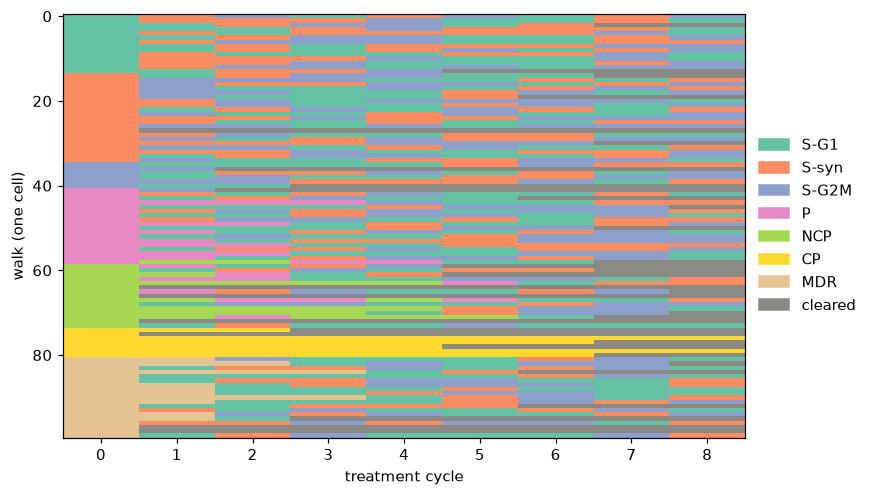

In [30]:
N_WALKS = 100
#N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [31]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

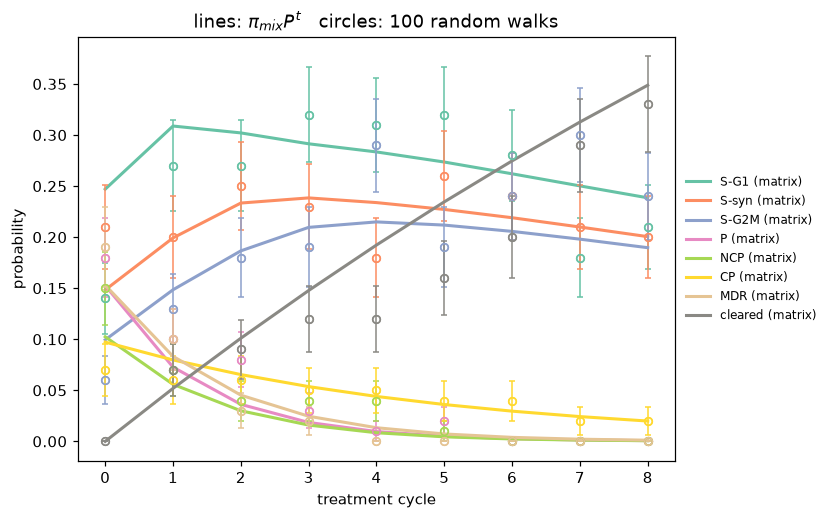

In [32]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

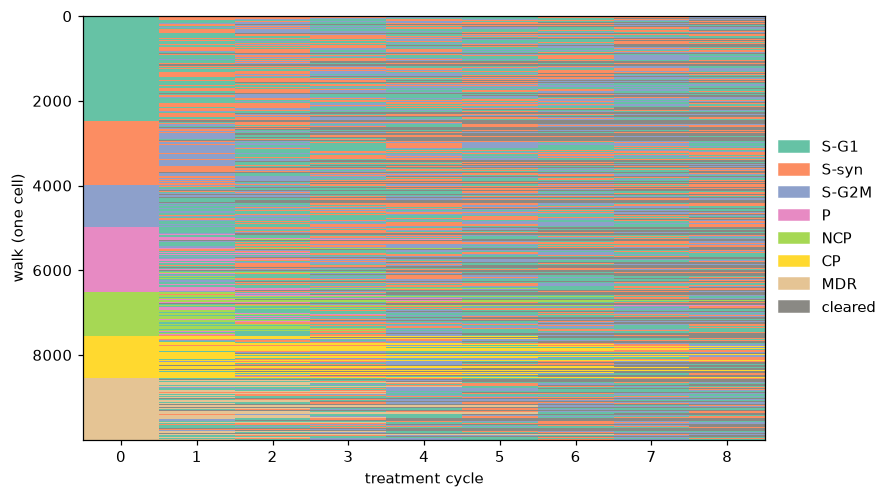

In [33]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [34]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

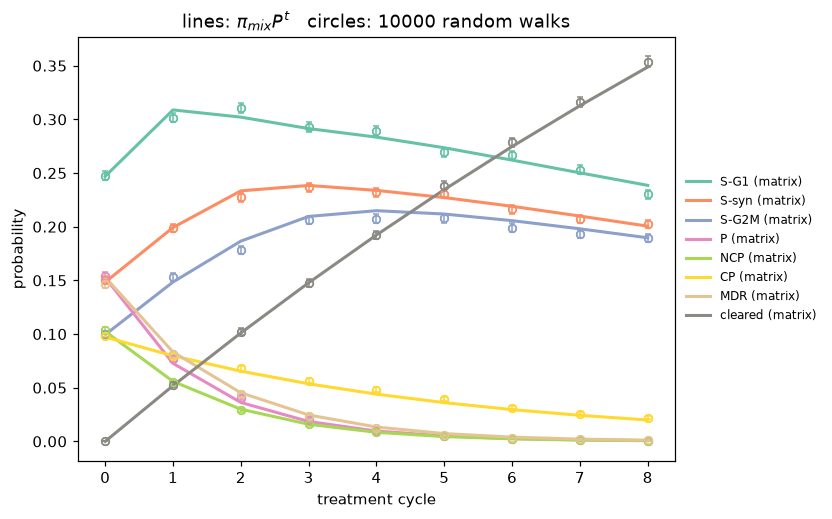

In [35]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

The gap between the circles and the lines becomes smaller. They used to be farther out when we did just 100 walks. This gap has changed because we are giving more data simulations to calculate these results. As we have more data to calculate the possibility of a cell being in that state, we have less random variation occuring. So, the results with the simulations will lie closer to the expected probabilities in our transition matrix too.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [36]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

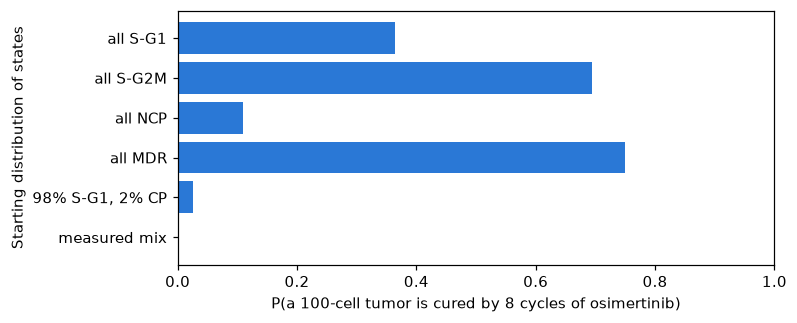

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [37]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

In [38]:
osi_results = results.copy()

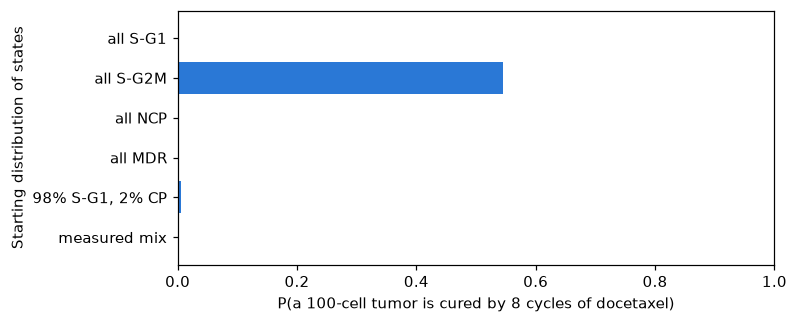

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [39]:

N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel

scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}

rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)


In [40]:

# Compare docetaxel with osimertinib

rows_doc = []

for name, pi0 in scenarios.items():

    # Simulate 200 tumors using docetaxel
    finals = np.array([
        simulate_tumor(pi0, P_doc, N_CELLS, N_TUMOR_CYCLES, rng)
        for _ in range(N_TUMORS)
    ])

    # Count the living cells in each tumor
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)

    # Calculate the proportion of completely cleared tumors
    rows_doc.append({
        "Starting tumor": name,
        "Docetaxel": np.mean(alive == 0)
    })

# Create a table
doc_results = pd.DataFrame(rows_doc).set_index("Starting tumor")

# Compare both treatments
comparison = pd.DataFrame({
    "Osimertinib": osi_results["P(cured)"],
    "Docetaxel": doc_results["Docetaxel"]
})

display(comparison.round(3))


,Osimertinib,Docetaxel
all S-G1,0.365,0.005
all S-G2M,0.695,0.580
all NCP,0.110,0.000
all MDR,0.750,0.000
"98% S-G1, 2% CP",0.025,0.000
measured mix,0.000,0.000


<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

It seems to me that each drug has a strength at sending the cells in some cell state to a cleared cell state. The use of osimertinib shows that a tumor made entirely of S-G2M has 69.5% chance of being cleared. Further, if the tumor is made up of the MDR cells, it has a chance of 75% being cleared under the use of the osmertinib procedure.

However, on docetaxel, we notice that tumors that are made entirely out of the S-G2M cells have a 58% chance of being cleared and tumors made entirely of S-G1 have a 0.5% chance of being cleared. We do not find any other percentage chances of the tumor being cleared with the other compositions in these 200 simulations confucted. So in total, we would find that the osmiertinib had a higher probability in clearing most different types of cell states in comparison to the docetaxel treatment.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [41]:

# 1. Write a function that runs 1000 random walks and saves them

def simulate_walks(P, n_cycles=8):

    starts = rng.choice(len(pi_mix), size=1000, p=pi_mix)

    walks = np.array([
        random_walk(int(s), P, n_cycles, rng)
        for s in starts
    ])

    return walks


# 2. Check if a cell stays in P or NCP for 3+ consecutive cycles

def check_resistance(walk):

    consecutive = 0

    for state in walk[1:]:

        if OUTCOMES[state] in ["P", "NCP"]:
            consecutive += 1
        else:
            consecutive = 0

        if consecutive >= 3:
            return True

    return False


# 3. Repeat for 100 tumors using osimertinib

tumor_results = []

for tumor in range(100):

    walks = simulate_walks(P_osi)

    resistant_cells = 0

    # Count permanently resistant cells
    for walk in walks:

        if check_resistance(walk):
            resistant_cells += 1

    # Proportion of resistant cells in the tumor
    proportion = resistant_cells / 1000

    tumor_results.append(proportion)


# 4. Report mean +/- SEM

tumor_results = np.array(tumor_results)

mean = tumor_results.mean()

sem = tumor_results.std(ddof=1) / np.sqrt(100)

print("Mean PR (%):", round(mean * 100, 2))
print("SEM (%):", round(sem * 100, 2))


# 5. Calculate the 95% confidence interval

lower = mean - 1.96 * sem
upper = mean + 1.96 * sem

print("95% CI:", round(lower * 100, 2),
      "to", round(upper * 100, 2), "%")


# 6. Compare the average with 10%

if lower > 0.10:
    print("The 95% CI is above 10%.")

elif upper < 0.10:
    print("The 95% CI is below 10%.")

else:
    print("The 95% CI includes 10%.")


# 7. Percentage of tumors with more than 10% PR cells

above_10 = (tumor_results > 0.10).mean() * 100

print("Tumors above 10% PR:", round(above_10, 1), "%")


Mean PR (%): 8.23
SEM (%): 0.09
95% CI: 8.05 to 8.4 %
The 95% CI is below 10%.
Tumors above 10% PR: 1.0 %


In [42]:

# 1. Run 1000 random walks for one tumor
# This version allows different drugs in different cycles

def simulate_schedule_walks(schedule, n_cycles):

    starts = rng.choice(len(pi_mix), size=1000, p=pi_mix)

    walks = []

    for start in starts:

        path = [int(start)]

        for cycle in range(n_cycles):

            P = schedule[cycle % len(schedule)]

            next_state = step(path[-1], P, rng)

            path.append(next_state)

        walks.append(path)

    return np.array(walks)


# 2. Define the four treatment schedules

treatments = {
    "Osimertinib": [P_osi],
    "Docetaxel": [P_doc],
    "Alternating O-D": [P_osi, P_doc],
    "Docetaxel + Holiday": [P_doc, P_holiday]
}


# 3. Test all treatments with different cycle counts

results = []

for treatment, schedule in treatments.items():

    for n_cycles in [4, 8, 12, 16]:

        tumor_results = []

        # Repeat the 1000-walk simulation 100 times
        for tumor in range(100):

            walks = simulate_schedule_walks(schedule, n_cycles)

            resistant_cells = 0

            for walk in walks:

                if check_resistance(walk):
                    resistant_cells += 1

            proportion = resistant_cells / 1000

            tumor_results.append(proportion)

        # Percentage of tumors exceeding 10% resistance
        tumor_results = np.array(tumor_results)

        above_10 = (tumor_results > 0.10).mean() * 100

        results.append({
            "Treatment": treatment,
            "Cycles": n_cycles,
            "Tumors above 10% PR (%)": round(above_10, 1)
        })


# 4. Display the comparison table

results_df = pd.DataFrame(results)

display(results_df.pivot(
    index="Treatment",
    columns="Cycles",
    values="Tumors above 10% PR (%)"
))


Cycles,4,8,12,16
Treatment,,,,
Alternating O-D,0.0,0.0,1.0,0.0
Docetaxel,0.0,0.0,0.0,0.0
Docetaxel + Holiday,0.0,0.0,1.0,0.0
Osimertinib,0.0,2.0,1.0,3.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

- Osimertinib alone

Under 4 treatment cycles, we notice that the percentage of tumors that have permanently resistant cells exceeding 10% is 0. Under 8 treatment cycles, we notice that 2.0% of tumors have more than 10% of permanently resistant cells. Under 12 treatment cycles, we notice that 1.0% of tumors have more than 10% of permanently resistant cells. Under 16 treatment cycles, we notice that 3.0% of tumors have more than 10% of permanently resistant cells. So, we can say that as the number of treatment cycles increases, the percentage of tumors that exceed 10% of permanently resistant cells basically increases. However, it is important to note that the percentage of permanently resistant cell tumors over 10% decreases from 8 treatment cycles to 12 treatment cycles.

- Doxetaxel alone

Under docetaxel, we do not notice any percentage of tumors that exceed 10% found under any number of treatment cycles. So, this means that as the number of treatment cycles increases, we did not notice the percentage of tumors with permanently resistant cells exceeding 10% either increase or decrease.

- Alternating OD

Under 12 treatment cycles, we notice that 1.0% of tumors had permanently resistant cells that exceeded 10%. However, we notice that under 4, 8, and 16 treatment cycles, we found 0% of tumors in the simulation having tumors that had the criteria stated. So, we notice that as the number of treatment cycles increased from 8 to 12, the number of tumors that had permanently resistant cells exceeding 10% increases. However, after 12 treatment cycles, we notice that this percentage decreases. Further we know that this inconsistent increasing and decreasing can be because of the randomness in the simulation, but we do not know for sure. It could also be because we were simulating new tumors under the 16 treatment cycle in comparison to the 12 treatment cycle. We do not know.

- Doxetaxel with drug holiday

Under docetaxel with drug holiday, we do not notice any percentage of tumors that exceed 10% found under any number of treatment cycles. So, this means that as the number of treatment cycles increases, we did not notice the percentage of tumors with permanently resistant cells exceeding 10% either increase or decrease.

I used ChatGPT to understand concepts in the problems and write code.